# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
path = Path("data/AviationData_Cleaned.csv")
if not path.exists():
    path = Path("AviationData_Cleaned.csv")
df = pd.read_csv(path, low_memory=False)
df["Event.Date"] = pd.to_datetime(df["Event.Date"], errors="coerce")
df = df[df["Event.Date"].dt.year.between(1983, 2023)].copy()
print("Loaded records:", len(df))
display(df.head())

Loaded records: 66851


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Airport.Code,Airport.Name,Injury.Severity,Aircraft.damage,...,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Destroyed,Aircraft_Type
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,...,0.0,0.0,1.0,3.0,VMC,APPROACH,Probable Cause,NaN,0.0,CESSNA - 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,3YR,MUNICIPAL,Non-Fatal,Substantial,...,0.0,0.0,0.0,2.0,VMC,LANDING,Probable Cause,NaN,0.0,CESSNA - 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,78Y,RANKIN,Non-Fatal,Substantial,...,0.0,0.0,0.0,1.0,VMC,TAKEOFF,Probable Cause,NaN,0.0,CESSNA - 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,CCB,CABLE,Non-Fatal,Substantial,...,0.0,0.0,2.0,0.0,VMC,APPROACH,Probable Cause,NaN,0.0,PIPER - PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,SPRINGBROOK,Non-Fatal,Substantial,...,0.0,0.0,0.0,2.0,VMC,LANDING,Probable Cause,NaN,0.0,CESSNA - 140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Prepare defensible accident-level safety metrics
for c in ["Total.Fatal.Injuries", "Total.Serious.Injuries", "Total.Minor.Injuries", "Total.Uninjured"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
injury_cols = ["Total.Fatal.Injuries", "Total.Serious.Injuries", "Total.Minor.Injuries", "Total.Uninjured"]
df["Total.Occupants"] = df[injury_cols].sum(axis=1, min_count=4)
df["Severe.Injuries"] = df["Total.Fatal.Injuries"] + df["Total.Serious.Injuries"]
df["Severe.Injury.Rate"] = (df["Severe.Injuries"] / df["Total.Occupants"]).where(df["Total.Occupants"] > 0)
df["Destroyed"] = pd.to_numeric(df["Destroyed"], errors="coerce")
# Keep known professionally built airplanes only; missing categories are not assumed to be airplanes.
professional = df["Amateur.Built"].astype("string").str.strip().str.upper().eq("NO").fillna(False)
airplane = df["Aircraft.Category"].astype("string").str.strip().str.upper().eq("AIRPLANE").fillna(False)
planes = df[professional & airplane].copy()
planes["Make"] = planes["Make"].astype("string").str.strip().str.upper()
planes["Model"] = planes["Model"].astype("string").str.strip().str.upper()
planes = planes.dropna(subset=["Make", "Model"])
planes["Aircraft_Type"] = planes["Make"] + " - " + planes["Model"]
planes["Size"] = np.where(planes["Total.Occupants"] <= 20, "Small", "Large")
# Only classify size when occupancy is known and positive
planes = planes[planes["Total.Occupants"] > 0].copy()
small = planes[planes["Size"] == "Small"].copy()
large = planes[planes["Size"] == "Large"].copy()
print("Professional airplanes with usable occupant counts:", len(planes))
print("Small (1-20 occupants):", len(small), "Large (>20 occupants):", len(large))
print("Note: These are accident records, not fleet-wide accident probabilities.")

Professional airplanes with usable occupant counts: 18967
Small (1-20 occupants): 18551 Large (>20 occupants): 416
Note: These are accident records, not fleet-wide accident probabilities.


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

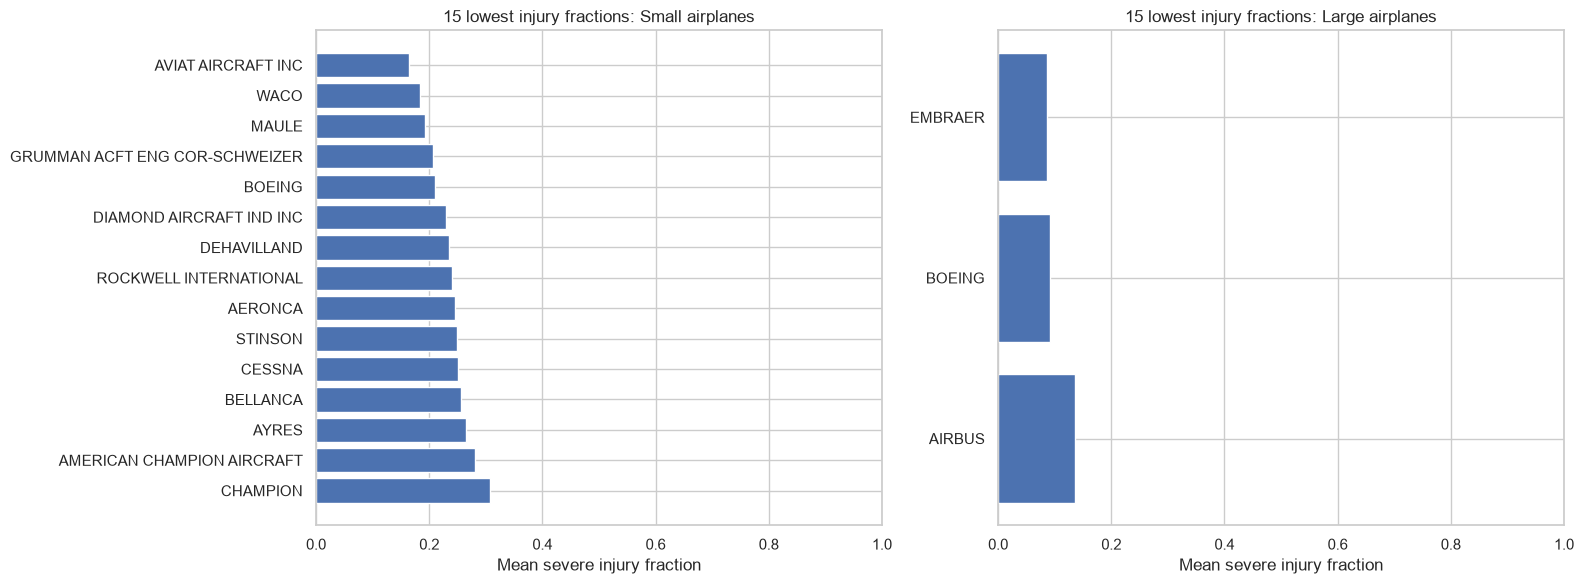

SMALL MAKES


,n,injury_rate,destroyed_rate,destruction_n
Make,,,,
AVIAT AIRCRAFT INC,76,0.164474,0.040000,75
WACO,31,0.182796,0.032258,31
MAULE,171,0.192593,0.040936,171
GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.206897,0.017241,58
BOEING,159,0.210167,0.131387,137
DIAMOND AIRCRAFT IND INC,72,0.229167,0.055556,72
DEHAVILLAND,92,0.234170,0.044944,89
ROCKWELL INTERNATIONAL,53,0.240566,0.132075,53
AERONCA,168,0.245040,0.041667,168


LARGE MAKES


,n,injury_rate,destroyed_rate,destruction_n
Make,,,,
EMBRAER,48,0.085764,0.148148,27
BOEING,253,0.092471,0.165289,121
AIRBUS,65,0.135157,0.235294,34


In [4]:
# At least 30 observed injury-rate records per manufacturer/size group
MIN_MAKE = 30
def make_summary(data):
    return (data.groupby("Make").agg(n=("Severe.Injury.Rate", "count"),
                injury_rate=("Severe.Injury.Rate", "mean"),
                destroyed_rate=("Destroyed", "mean"),
                destruction_n=("Destroyed", "count"))
            .query("n >= @MIN_MAKE").sort_values("injury_rate"))
small_makes = make_summary(small)
large_makes = make_summary(large)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, data, title in [(axes[0], small_makes, "Small airplanes"),
                         (axes[1], large_makes, "Large airplanes")]:
    top = data.head(15).sort_values("injury_rate")
    ax.barh(top.index[::-1], top["injury_rate"].iloc[::-1])
    ax.set(title=f"15 lowest injury fractions: {title}", xlabel="Mean severe injury fraction", xlim=(0, 1))
plt.tight_layout(); plt.show()
print("SMALL MAKES"); display(small_makes.head(15))
print("LARGE MAKES"); display(large_makes.head(15))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

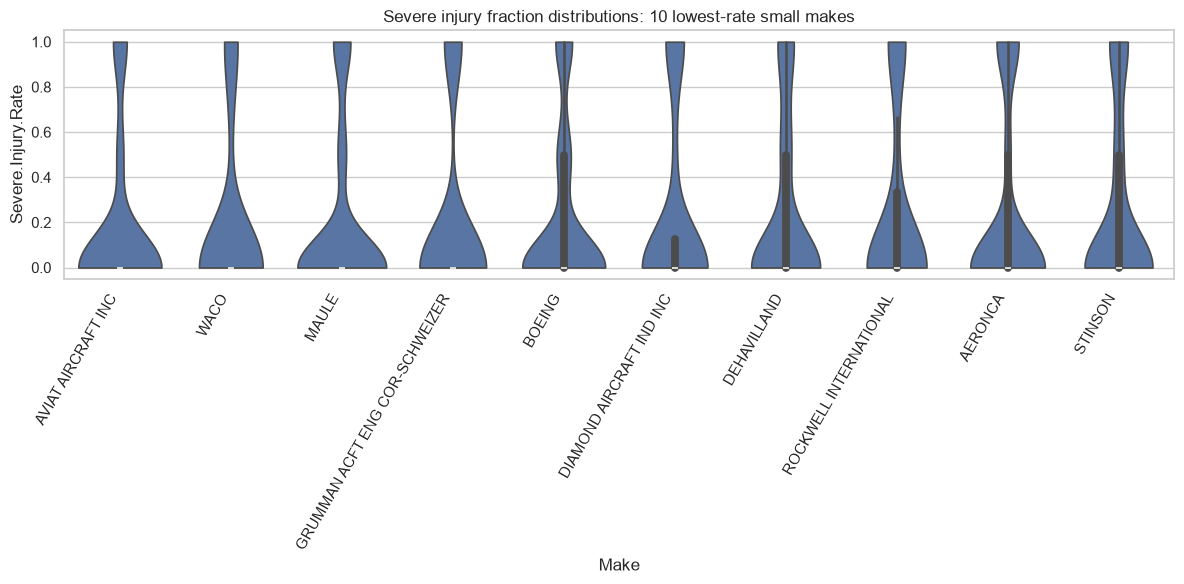

In [5]:
top_small = small_makes.head(10).index
plot_small = small[small["Make"].isin(top_small) & small["Severe.Injury.Rate"].notna()]
plt.figure(figsize=(12, 6))
if len(plot_small):
    sns.violinplot(data=plot_small, x="Make", y="Severe.Injury.Rate", order=list(top_small), cut=0)
    plt.xticks(rotation=60, ha="right")
    plt.title("Severe injury fraction distributions: 10 lowest-rate small makes")
else: print("Insufficient qualifying small-airplane manufacturers")
plt.tight_layout(); plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

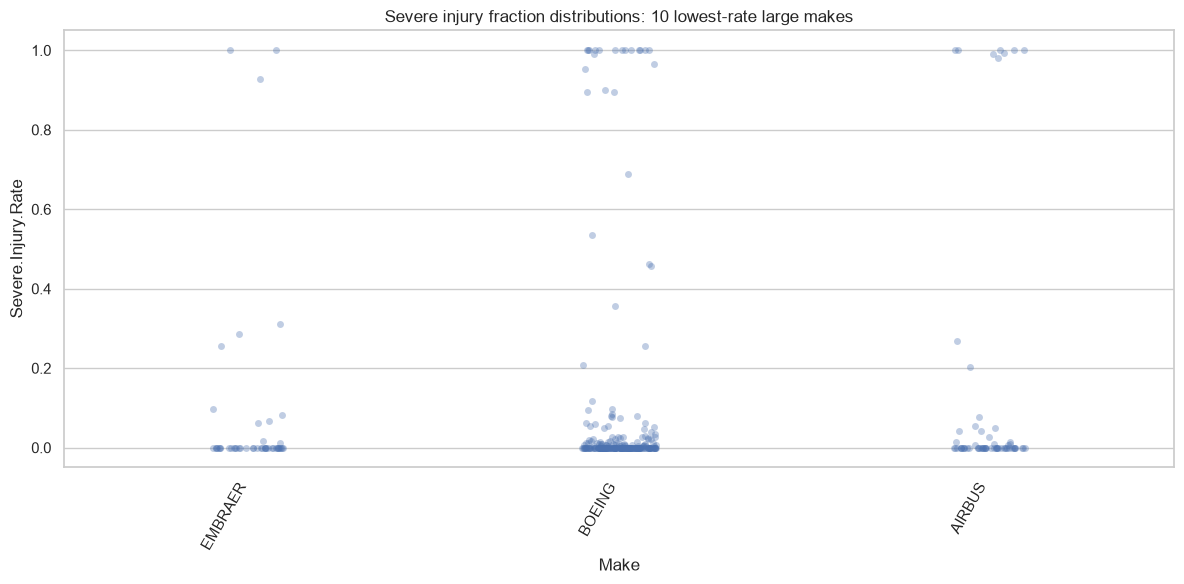

In [6]:
top_large = large_makes.head(10).index
plot_large = large[large["Make"].isin(top_large) & large["Severe.Injury.Rate"].notna()]
plt.figure(figsize=(12, 6))
if len(plot_large):
    sns.stripplot(data=plot_large, x="Make", y="Severe.Injury.Rate", order=list(top_large), jitter=True, alpha=.35)
    plt.xticks(rotation=60, ha="right")
    plt.title("Severe injury fraction distributions: 10 lowest-rate large makes")
else: print("Insufficient qualifying large-airplane manufacturers")
plt.tight_layout(); plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

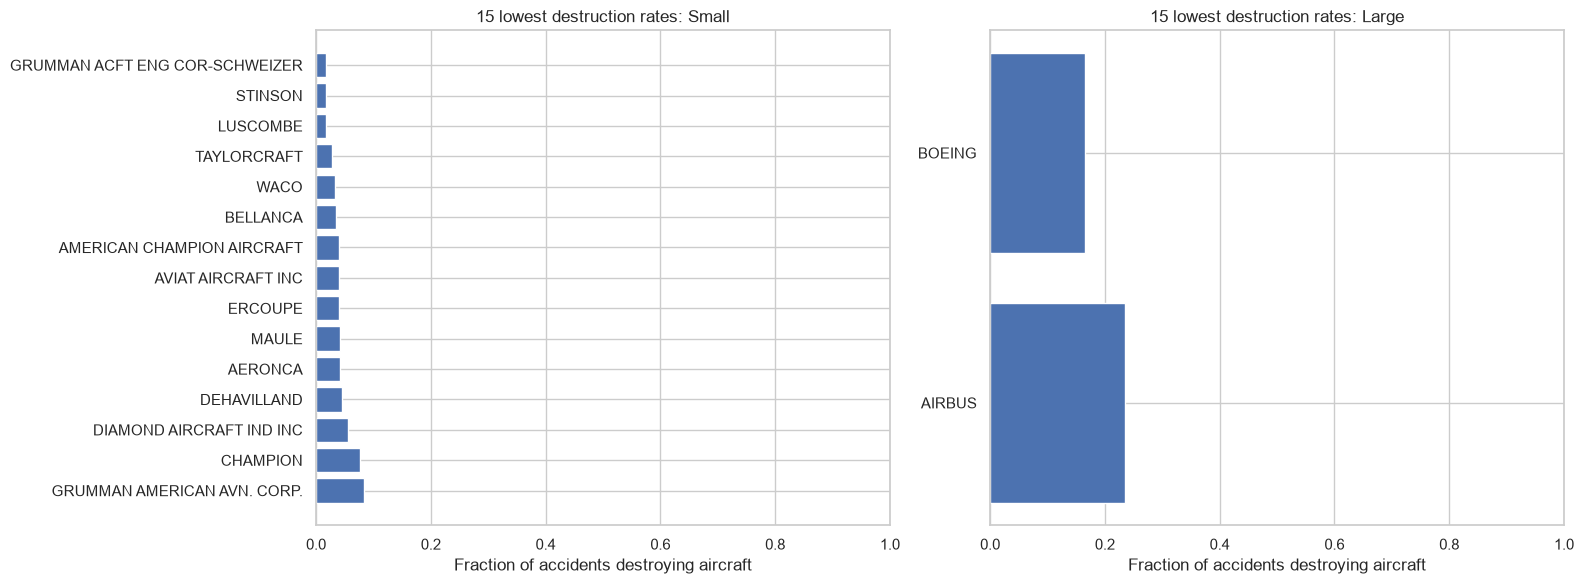

SMALL DESTRUCTION


,count,mean
Make,,
GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.017241
STINSON,112,0.017857
LUSCOMBE,112,0.017857
TAYLORCRAFT,73,0.027397
WACO,31,0.032258
BELLANCA,175,0.034286
AMERICAN CHAMPION AIRCRAFT,50,0.040000
AVIAT AIRCRAFT INC,75,0.040000
ERCOUPE,49,0.040816


LARGE DESTRUCTION


,count,mean
Make,,
BOEING,121,0.165289
AIRBUS,34,0.235294


In [7]:
# Destruction fractions are based on nonmissing destruction outcomes
MIN_DAMAGE = 30
def damage_summary(data):
    x = data.groupby("Make")["Destroyed"].agg(["count", "mean"])
    return x[x["count"] >= MIN_DAMAGE].sort_values("mean").head(15)
small_damage = damage_summary(small)
large_damage = damage_summary(large)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, result, label in [(axes[0], small_damage, "Small"), (axes[1], large_damage, "Large")]:
    ax.barh(result.index[::-1], result["mean"].iloc[::-1])
    ax.set(xlabel="Fraction of accidents destroying aircraft", title=f"15 lowest destruction rates: {label}", xlim=(0,1))
plt.tight_layout(); plt.show()
print("SMALL DESTRUCTION"); display(small_damage)
print("LARGE DESTRUCTION"); display(large_damage)

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Manufacturer findings and recommendations
The charts compare **outcomes conditional on a recorded accident**, not the probability that an aircraft will have an accident. The mean injury fraction measures the proportion of occupants fatally or seriously injured in each accident, averaged across accidents. The destruction fraction is the proportion of accidents resulting in a destroyed aircraft. Only manufacturers with at least 30 valid observations for each comparison are ranked.

Use the displayed tables to identify manufacturers appearing near the top of **both** low-injury and low-destruction rankings. The violin and strip plots show variation and outliers: a low average does not guarantee consistently low injury severity. Comparisons may also reflect differences in aircraft use, weather, operating environment, and accident reporting rather than intrinsic design safety. The sample is limited to records explicitly categorized as professionally built airplanes.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

,n,mean
Aircraft_Type,,
BOEING - 777,10,0.001826
BOEING - 757,10,0.002651
BOEING - 737 7H4,12,0.079474
BOEING - 767,18,0.080531
BOEING - 737,75,0.175361
AIRBUS - A320,10,0.200577


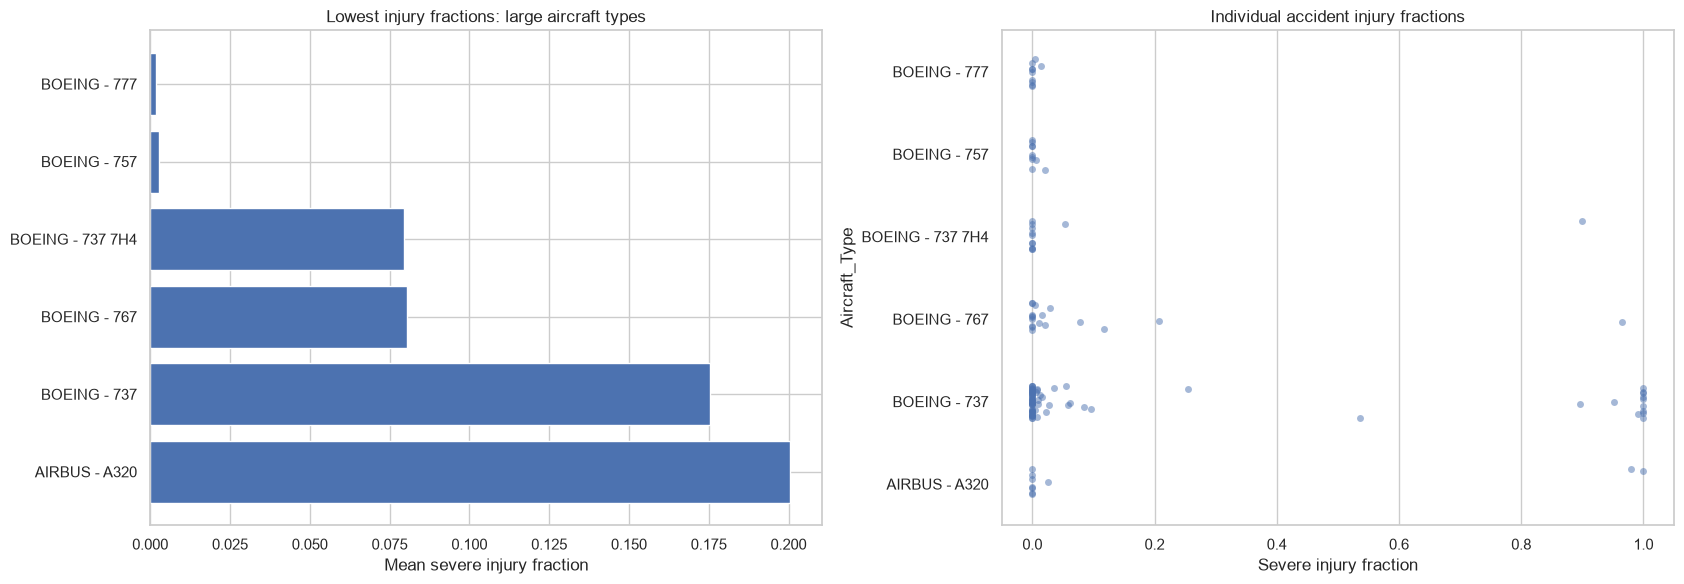

In [8]:
# Large aircraft types: at least 10 accident records with known injury fractions
MIN_MODEL = 10
large_types = (large.groupby("Aircraft_Type")["Severe.Injury.Rate"]
               .agg(n="count", mean="mean").query("n >= @MIN_MODEL")
               .sort_values("mean"))
display(large_types.head(20))
selected_large = large_types.head(10).index
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
if len(selected_large):
    axes[0].barh(list(selected_large)[::-1], large_types.loc[selected_large, "mean"].iloc[::-1])
    sns.stripplot(data=large[large["Aircraft_Type"].isin(selected_large)],
                  x="Severe.Injury.Rate", y="Aircraft_Type", order=list(selected_large),
                  alpha=.5, jitter=.2, ax=axes[1])
axes[0].set(title="Lowest injury fractions: large aircraft types", xlabel="Mean severe injury fraction")
axes[1].set(title="Individual accident injury fractions", xlabel="Severe injury fraction")
plt.tight_layout(); plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

,n,mean
Aircraft_Type,,
DIAMOND AIRCRAFT IND INC - DA 20 C1,11,0.000000
BOEING - 737,15,0.066667
AERONCA - 15AC,10,0.100000
STINSON - 108-1,13,0.102564
MAULE - MX7,18,0.125000
MAULE - M-5-235C,11,0.136364
BOEING - A75N1(PT17),30,0.144444
AERONCA - 7CCM,10,0.166667
AVIAT AIRCRAFT INC - A-1B,22,0.181818


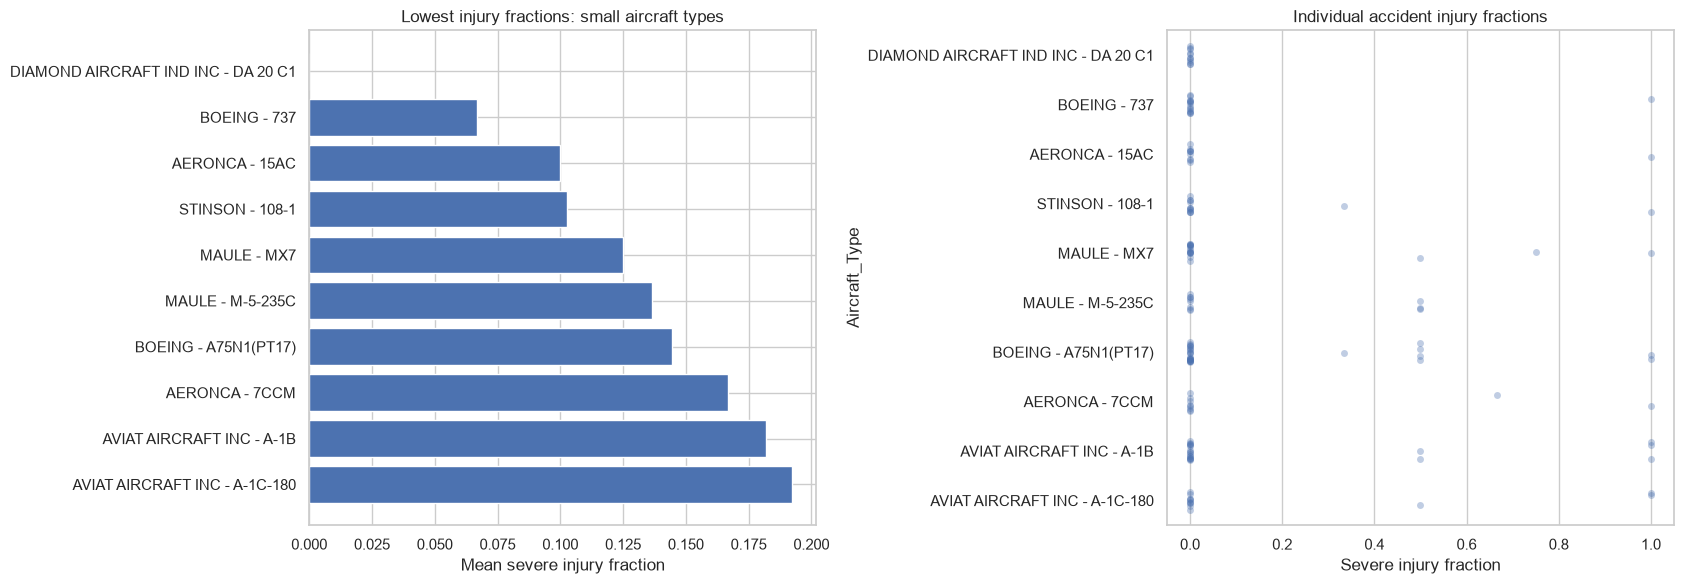

In [9]:
# Small types restricted to the ten lowest-mean small manufacturers
small_types = (small[small["Make"].isin(top_small)]
               .groupby("Aircraft_Type")["Severe.Injury.Rate"]
               .agg(n="count", mean="mean").query("n >= @MIN_MODEL")
               .sort_values("mean"))
display(small_types.head(20))
selected_small = small_types.head(10).index
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
if len(selected_small):
    axes[0].barh(list(selected_small)[::-1], small_types.loc[selected_small, "mean"].iloc[::-1])
    sns.stripplot(data=small[small["Aircraft_Type"].isin(selected_small)],
                  x="Severe.Injury.Rate", y="Aircraft_Type", order=list(selected_small),
                  alpha=.35, jitter=.2, ax=axes[1])
axes[0].set(title="Lowest injury fractions: small aircraft types", xlabel="Mean severe injury fraction")
axes[1].set(title="Individual accident injury fractions", xlabel="Severe injury fraction")
plt.tight_layout(); plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion of specific airplane types
The tables rank aircraft types using **at least 10 accidents with valid injury fractions per type**. The charts display both average severity and variation across individual accidents. Low averages can conceal severe outliers, particularly for types with small sample sizes. For the insurer's shortlist, prioritize types with low observed mean injury fractions, sufficient sample sizes, and supporting low destruction rates. These findings are descriptive: the dataset does not contain the total flights or operating hours needed to establish a true accident risk by model.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.


FACTOR: Weather.Condition


,accidents,injury_n,mean_injury_fraction,destruction_n,destruction_fraction
Weather.Condition,,,,,
VMC,16325,16325,0.240,16134,0.100
IMC,1053,1053,0.669,1020,0.445


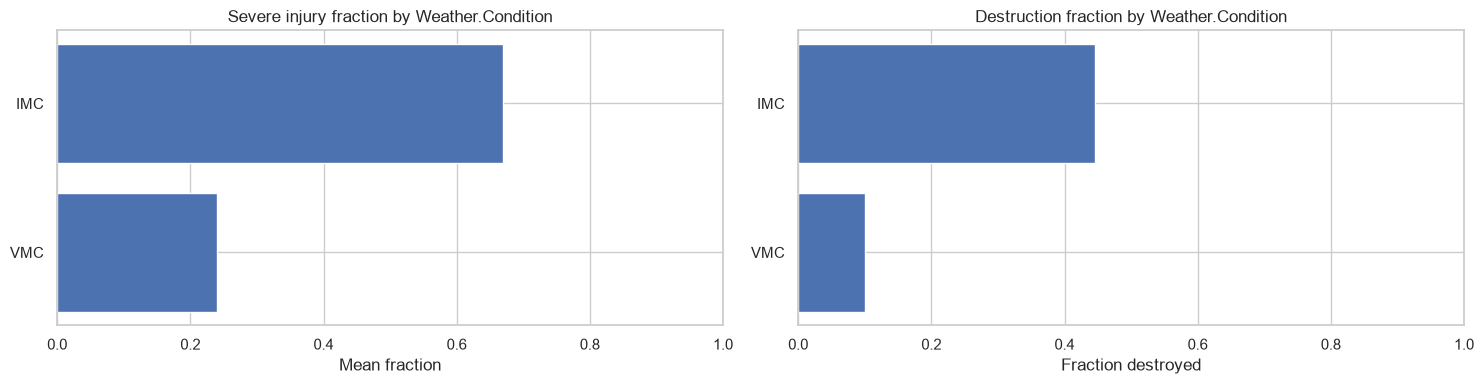


FACTOR: Broad.phase.of.flight


,accidents,injury_n,mean_injury_fraction,destruction_n,destruction_fraction
Broad.phase.of.flight,,,,,
TAXI,154,154,0.019,154,0.032
LANDING,1546,1546,0.030,1546,0.046
STANDING,61,61,0.152,50,0.180
TAKEOFF,877,877,0.180,877,0.186
GO-AROUND,181,181,0.222,181,0.210
CRUISE,780,780,0.282,779,0.300
APPROACH,409,409,0.285,407,0.297
DESCENT,118,118,0.318,117,0.359
CLIMB,118,118,0.345,118,0.364


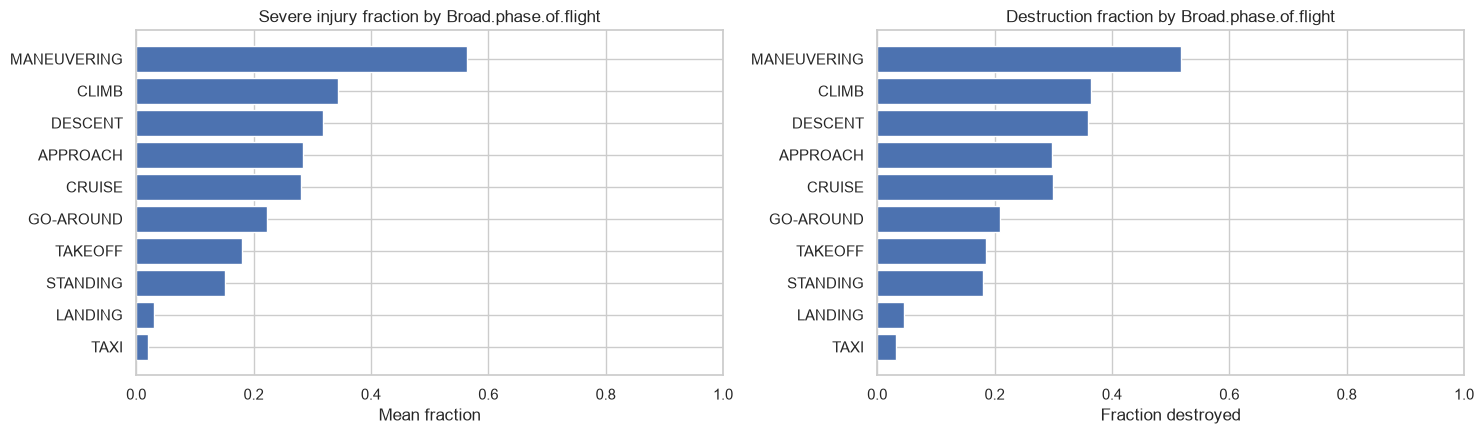

Interpretation: Compare the factor groups in the tables and charts above. Higher bars indicate
more severe outcomes among reported accidents, NOT higher probability of an accident.
Associations are observational and may be confounded by aircraft type and operating conditions.


In [10]:
# Examine TWO factors: weather conditions and phase of flight
factors = ["Weather.Condition", "Broad.phase.of.flight"]
for factor in factors:
    subset = planes.copy()
    subset[factor] = subset[factor].astype("string").str.strip().str.upper()
    subset = subset[subset[factor].notna() & ~subset[factor].isin(["UNKNOWN", "UNK", ""])]
    summary = (subset.groupby(factor)
               .agg(accidents=("Event.Id", "size"),
                    injury_n=("Severe.Injury.Rate", "count"),
                    mean_injury_fraction=("Severe.Injury.Rate", "mean"),
                    destruction_n=("Destroyed", "count"),
                    destruction_fraction=("Destroyed", "mean")))
    summary = summary[(summary["injury_n"] >= 20) & (summary["destruction_n"] >= 20)]
    summary = summary.sort_values("mean_injury_fraction")
    print("\nFACTOR:", factor)
    display(summary.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(15, max(4, len(summary)*.45)))
    if not summary.empty:
        axes[0].barh(summary.index, summary["mean_injury_fraction"])
        axes[1].barh(summary.index, summary["destruction_fraction"])
    axes[0].set(title=f"Severe injury fraction by {factor}", xlabel="Mean fraction", xlim=(0,1))
    axes[1].set(title=f"Destruction fraction by {factor}", xlabel="Fraction destroyed", xlim=(0,1))
    plt.tight_layout(); plt.show()
print("Interpretation: Compare the factor groups in the tables and charts above. Higher bars indicate")
print("more severe outcomes among reported accidents, NOT higher probability of an accident.")
print("Associations are observational and may be confounded by aircraft type and operating conditions.")



### Final insurer recommendations and limitations

**Small-aircraft shortlist:** Investigate **Aviat Aircraft Inc**, **Maule**, and **Grumman Acft Eng Cor-Schweizer** further because their observed serious/fatal injury fractions and destruction fractions were comparatively low in this sample. **Waco** also performed favorably but had fewer records. At the model level, **Cessna 180J**, **Piper PA-20**, and **Diamond DA 20 C1** are interesting candidates for further review, subject to model availability and sample-size checks.

**Large-aircraft shortlist:** **Embraer** had the lowest observed mean serious/fatal injury fraction, while **Boeing** had a similarly low injury fraction with a larger sample and the lowest destruction fraction among the large makes meeting the 30-known-damage-record threshold. **Boeing 757, 767 and 777** warrant further model-level investigation, but their small and incomplete damage samples prevent firm conclusions.

**Crucial limitations:** The analysis includes only accidents, not all flights or aircraft exposure, so it cannot establish actual accident likelihood or overall aircraft safety. Many aircraft categories were missing and were conservatively excluded. Occupants on a recorded accident were used as a proxy for aircraft size; this can misclassify lightly occupied large aircraft. The injury figures include all reported occupants, not necessarily passengers only. Missing injury and damage data, uneven sample sizes, and changing aircraft variants may bias comparisons. Weather and flight-phase associations are descriptive, not causal. These findings should guide further underwriting research, not serve as stand-alone insurance pricing decisions.
